# 04 — Modèle de prédiction du retard de livraison

**Question métier (logistique)** : quelle commande risque d'arriver en retard ?

**Objectif** : au moment où le client passe commande, estimer le risque que la livraison arrive après la date promise, pour agir *avant* l'avis négatif (le notebook 02 a montré qu'un retard fait chuter la note de 4,3 à 2,3).

Le code est dans `src/shoppulse/features.py` (variables) et `src/shoppulse/delay_model.py` (modèles). Le pipeline `pipelines/train_flow.py` entraîne le modèle final et écrit `docs/delay_model_report.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from shoppulse.delay_model import (
    TEST_START,
    DelayModelFactory,
    DelayModelTrainer,
)
from shoppulse.features import FEATURES, TARGET, DelayFeatureBuilder
from shoppulse.warehouse import DataWarehouse

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 160)
warehouse = DataWarehouse()

## 1. La cible : un retard qui varie beaucoup dans le temps

Une commande est **en retard** si elle est livrée après le jour promis au client. On ne garde que les commandes livrées (la cible n'est connue que pour elles).

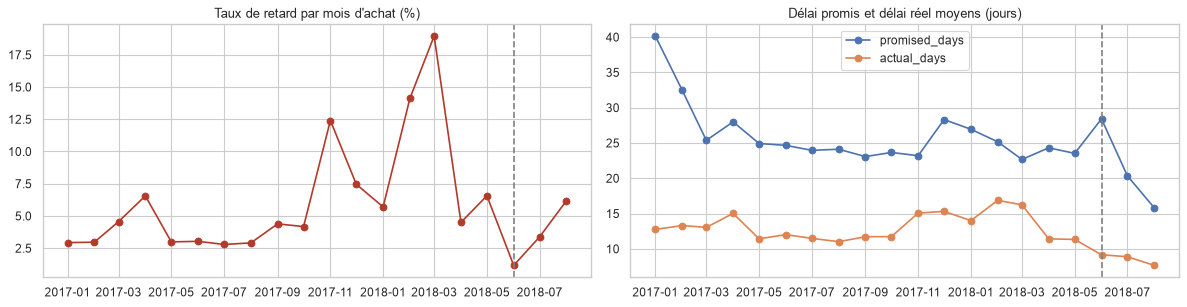

In [2]:
MONTHLY_SQL = """
SELECT DATE_TRUNC('month', purchase_timestamp)::DATE AS month,
    AVG(estimated_delivery_date::DATE - purchase_timestamp::DATE)
        AS promised_days,
    AVG(delivered_customer_date::DATE - purchase_timestamp::DATE)
        AS actual_days,
    100 * AVG((delivered_customer_date::DATE
        > estimated_delivery_date::DATE)::INT) AS late_pct
FROM core.orders
WHERE status = 'delivered' AND delivered_customer_date IS NOT NULL
    AND purchase_timestamp >= '2017-01-01'
    AND purchase_timestamp < '2018-09-01'
GROUP BY 1 ORDER BY 1
"""
monthly = warehouse.query(MONTHLY_SQL).set_index("month")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
monthly["late_pct"].plot(ax=axes[0], marker="o", color="#B23A2B")
axes[0].axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--")
axes[0].set(title="Taux de retard par mois d'achat (%)", xlabel="")
monthly[["promised_days", "actual_days"]].plot(ax=axes[1], marker="o")
axes[1].axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--")
axes[1].set(title="Délai promis et délai réel moyens (jours)", xlabel="")
plt.tight_layout()
plt.show()

**Lecture** : le taux de retard passe de 1 % à 19 % selon les mois, avec des pics en novembre 2017 (Black Friday) et en février-mars 2018. Pendant la période de test (après la ligne pointillée), Olist **raccourcit fortement ses délais promis** : 28 jours en juin, 20 en juillet, 16 en août, contre environ 24 avant, alors que le délai réel ne baisse que de 9 à 8 jours. La marge entre promesse et réalité fond.

**Conséquences sur la méthode** :
1. **découpage temporel** : on apprend sur janvier 2017 → mai 2018 et on teste sur juin → août 2018, comme en production où l'on prédit des commandes futures ;
2. **aucune fuite d'information** : chaque variable n'utilise que ce qui est connu au moment de l'achat ;
3. la variable clé doit relier la promesse au délai réellement observé, puisque c'est leur écart qui fait le retard.

## 2. Les variables (feature engineering)

| Variable | Ce qu'elle mesure | Pourquoi |
|---|---|---|
| `distance_km` | distance client-vendeur à vol d'oiseau | plus c'est loin, plus il y a d'étapes (requête SQL 04) |
| `same_state` | client et vendeur dans le même état | livraison locale, plus simple |
| `customer_state` | état du client | les retards varient fortement selon l'état (requête SQL 03) |
| `estimated_days` | délai promis au client | une promesse courte laisse moins de marge |
| `route_expected_days` | délai réel moyen des livraisons des 60 derniers jours sur le même trajet (état vendeur → état client) | ce que la promesse devrait couvrir |
| `promise_slack_days` | **marge de la promesse** = délai promis − délai attendu du trajet | le retard naît d'une marge insuffisante |
| `n_items`, `total_weight_g`, `order_value`, `freight_value` | taille, poids, valeur et frais de port du colis | colis lourds ou multiples plus difficiles à acheminer |
| `seller_past_orders` | nombre de commandes passées du vendeur | expérience du vendeur |
| `seller_past_late_rate` | taux de retard passé du vendeur (lissé vers 5 %) | un vendeur souvent en retard le reste |
| `seller_dispatch_days` | délai habituel du vendeur pour remettre le colis au transporteur | la préparation consomme la marge |
| `platform_delivery_days_14d` | délai moyen des livraisons des 14 derniers jours sur toute la plateforme | état actuel du réseau |
| `platform_orders_7d` | commandes des 7 derniers jours | engorgement (Black Friday) |

**Comment on évite les fuites** : les historiques (vendeur, trajet, plateforme) ne comptent que les événements **déjà connus à la date d'achat**. Une livraison est connue le jour où elle a lieu ; le statut « en retard » est connu dès la livraison si elle arrive à temps, sinon dès le lendemain de la date promise (colonne `known_at`). Le calcul est fait par la classe `TimeAwareHistory` (cumuls + `merge_asof`).

In [3]:
frame = DelayFeatureBuilder(warehouse).build()
print(f"{len(frame):,} commandes livrées, "
      f"{100 * frame[TARGET].mean():.1f} % en retard")
frame[FEATURES].describe().T.round(1)

96,203 commandes livrées, 6.8 % en retard


,count,mean,std,min,25%,50%,75%,max
distance_km,95724.0,600.3,592.2,0.0,185.8,433.8,798.1,3399.2
same_state,96203.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
estimated_days,96203.0,24.3,8.6,3.0,19.0,24.0,29.0,156.0
route_expected_days,96203.0,12.6,5.0,5.8,9.0,11.5,15.4,46.9
promise_slack_days,96203.0,11.7,7.2,-19.9,7.0,11.1,15.3,141.1
n_items,96203.0,1.1,0.5,1.0,1.0,1.0,1.0,21.0
total_weight_g,96187.0,2386.3,4771.6,0.0,300.0,750.0,2050.0,184400.0
order_value,96203.0,137.0,209.1,0.8,45.9,86.5,149.9,13440.0
freight_value,96203.0,22.8,21.6,0.0,13.8,17.2,24.0,1795.0
seller_past_orders,96203.0,170.2,283.9,0.0,12.0,52.0,181.0,1789.0


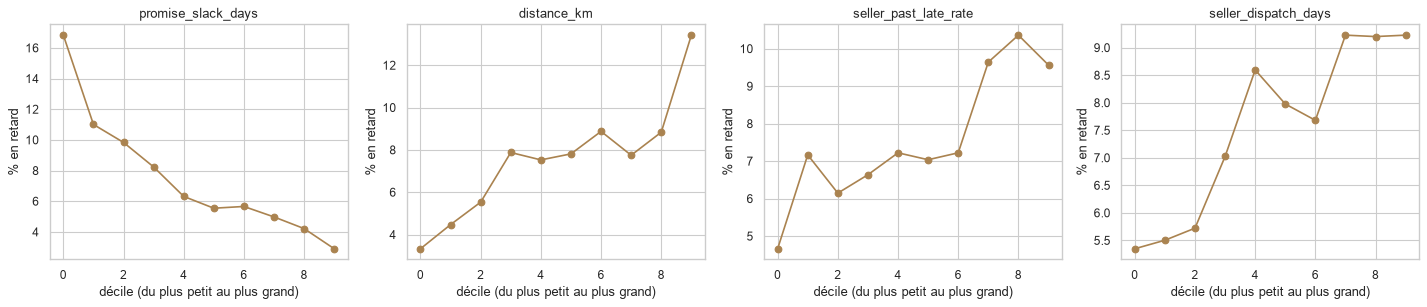

In [4]:
train_period = frame[frame["purchase_timestamp"] < TEST_START]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, column in zip(axes, ["promise_slack_days", "distance_km",
                             "seller_past_late_rate",
                             "seller_dispatch_days"]):
    deciles = pd.qcut(train_period[column], 10, duplicates="drop")
    rates = train_period.groupby(deciles, observed=True)[TARGET].mean()
    ax.plot(range(len(rates)), 100 * rates.to_numpy(), marker="o",
            color="#AA8350")
    ax.set(title=column, xlabel="décile (du plus petit au plus grand)",
           ylabel="% en retard")
plt.tight_layout()
plt.show()

**Lecture** (période d'apprentissage) : le risque baisse nettement quand la marge de la promesse augmente, et il augmente avec la distance, le taux de retard passé du vendeur et son délai de préparation. Les variables vont dans le sens attendu.

## 3. Protocole d'évaluation

- **Découpage temporel** : apprentissage avant le 1er juin 2018, test ensuite (jamais utilisé pour choisir quoi que ce soit).
- **Validation croisée temporelle** (`TimeSeriesSplit`, 5 plis) sur la période d'apprentissage : chaque pli apprend sur le passé et valide sur les mois suivants. Une validation croisée classique mélangerait passé et futur et serait trop optimiste.
- **Métriques adaptées au déséquilibre** (environ 7 % de retards ; l'exactitude n'a pas de sens : prédire « jamais en retard » donne 93 %) :
  - **PR-AUC** (aire sous la courbe précision-rappel) : métrique principale ; un modèle au hasard obtient le taux de retard ;
  - **ROC-AUC** : capacité à classer un retard avant une commande à l'heure (0,5 = hasard) ;
  - **rappel top 10 %** : part des retards captés en surveillant les 10 % de commandes les plus risquées (hasard = 10 %).
- **Baselines** : le taux de retard moyen (aucune information) et une règle métier simple, le taux de retard historique de l'état du client.
- **Deux algorithmes** : régression logistique (linéaire, interprétable) et gradient boosting d'arbres (non linéaire). Les deux compensent le déséquilibre avec `class_weight="balanced"`.

In [5]:
trainer = DelayModelTrainer(frame)
pd.Series(trainer.sizes()).round(3)

train_orders       77600.000
train_late_rate        0.076
test_orders        18603.000
test_late_rate         0.036
dtype: float64

## 4. Réglage du gradient boosting

Deux configurations comparées en validation croisée : standard (arbres de 31 feuilles) et régularisée (15 feuilles, au moins 400 commandes par feuille, pénalité L2 plus forte).

In [6]:
tuning = DelayModelTrainer(frame)
tuning.candidates = {
    "boosting_standard": DelayModelFactory.boosting(regularized=False),
    "boosting_regularise": DelayModelFactory.boosting(),
}
DelayModelTrainer.summarize(tuning.cross_validate()).round(3)

pr_auc        roc_auc        recall_top10        precision_top10       
                      mean    std    mean    std         mean    std            mean    std
model                                                                                      
boosting_regularise  0.177  0.110   0.700  0.037        0.271  0.048           0.217  0.142
boosting_standard    0.170  0.117   0.691  0.041        0.252  0.044           0.210  0.150

La version régularisée est meilleure en validation : comme les données changent avec le temps, un modèle trop flexible apprend des détails qui ne durent pas. C'est elle qui est comparée ensuite.

## 5. Comparaison des modèles en validation croisée

In [7]:
results = trainer.run()
summary = DelayModelTrainer.summarize(results.cv_scores)
summary.round(3)

pr_auc        roc_auc        recall_top10        precision_top10       
                        mean    std    mean    std         mean    std            mean    std
model                                                                                        
gradient_boosting      0.177  0.110   0.700  0.037        0.271  0.048           0.217  0.142
regression_logistique  0.159  0.108   0.658  0.119        0.250  0.080           0.196  0.135
regle_taux_par_etat    0.133  0.083   0.639  0.017        0.176  0.038           0.145  0.111
baseline_taux_moyen    0.083  0.056   0.500  0.000        0.096  0.005           0.080  0.055

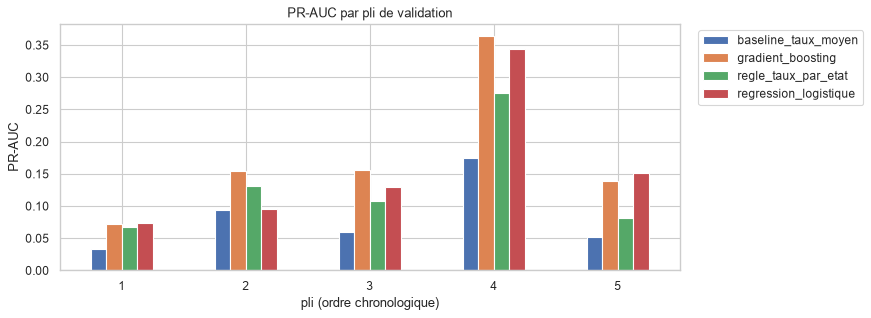

In [8]:
by_fold = results.cv_scores.pivot(index="fold", columns="model",
                                  values="pr_auc")
ax = by_fold.plot.bar(figsize=(10, 4), rot=0)
ax.set(title="PR-AUC par pli de validation", xlabel="pli (ordre "
       "chronologique)", ylabel="PR-AUC")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Lecture** : le gradient boosting est le meilleur en moyenne (PR-AUC ≈ 0,18, soit environ 2 fois la baseline ; ROC-AUC ≈ 0,70) et aussi le plus **stable** d'un pli à l'autre (écart-type de ROC-AUC 3 fois plus faible que la régression logistique). En surveillant 10 % des commandes, il capte environ 27 % des retards, contre 10 % au hasard. Le pli 4 (février → avril 2018, 17 % de retards) tire toutes les PR-AUC vers le haut. **Modèle retenu : gradient boosting.**

## 6. Choix du seuil de décision

Le modèle donne une probabilité ; pour décider « à surveiller / pas à surveiller », on fixe un seuil sur les prédictions de **validation** (jamais sur le test) : celui qui maximise le F1.

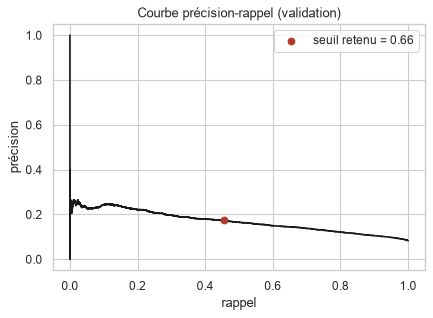

In [9]:
best = results.best_model
oof = trainer.oof_predictions[best]
mask = ~np.isnan(oof)
precision, recall, thresholds = precision_recall_curve(
    trainer.train[TARGET].to_numpy()[mask], oof[mask]
)
chosen = np.searchsorted(thresholds, results.threshold)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision, color="#1A1A17")
ax.scatter(recall[chosen], precision[chosen], color="#B23A2B", zorder=3,
           label=f"seuil retenu = {results.threshold:.2f}")
ax.set(title="Courbe précision-rappel (validation)", xlabel="rappel",
       ylabel="précision")
ax.legend()
plt.show()

## 7. Évaluation finale sur le test (juin → août 2018)

In [10]:
results.test_scores.round(3)

,pr_auc,roc_auc,recall_top10,precision_top10,precision,recall,f1,balanced_accuracy,flagged_share
model,,,,,,,,,
regression_logistique,0.075,0.709,0.216,0.078,NaN,NaN,NaN,NaN,NaN
gradient_boosting,0.060,0.651,0.174,0.063,0.057,0.214,0.09,0.541,0.136
regle_taux_par_etat,0.037,0.455,0.095,0.034,NaN,NaN,NaN,NaN,NaN
baseline_taux_moyen,0.036,0.500,0.103,0.037,NaN,NaN,NaN,NaN,NaN


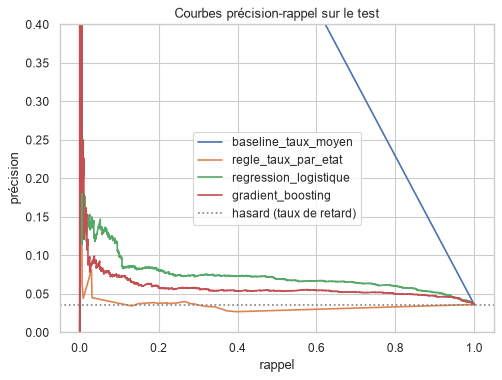

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
y_test = results.test_predictions[TARGET]
for column in [c for c in results.test_predictions if
               c.startswith("proba_")]:
    p, r, _ = precision_recall_curve(y_test, results.test_predictions[column])
    ax.plot(r, p, label=column.removeprefix("proba_"))
ax.axhline(y_test.mean(), color="grey", linestyle=":",
           label="hasard (taux de retard)")
ax.set(title="Courbes précision-rappel sur le test", xlabel="rappel",
       ylabel="précision", ylim=(0, 0.4))
ax.legend()
plt.show()

In [12]:
flagged = results.test_predictions[f"proba_{best}"] >= results.threshold
pd.crosstab(
    y_test.map({0: "à l'heure", 1: "en retard"}),
    flagged.map({False: "non signalée", True: "signalée"}),
    rownames=["réalité"], colnames=["prédiction"], margins=True,
)

prédiction,non signalée,signalée,All
réalité,,,
en retard,528,144,672
à l'heure,15551,2380,17931
All,16079,2524,18603


**Lecture honnête** : sur l'été 2018, les performances baissent nettement par rapport à la validation. Le gradient boosting reste meilleur que les deux baselines (PR-AUC ≈ 0,06 contre 0,036 ; rappel top 10 % ≈ 17 % contre 10 %), mais la **régression logistique fait mieux que lui sur cette période** (PR-AUC ≈ 0,075, ROC-AUC ≈ 0,71). La règle par état devient même pire que le hasard : les états « à risque » d'avant ne le sont plus.

On **ne change pas** de modèle après avoir vu le test : ce serait choisir sur le test et rendre l'évaluation trop optimiste. On retient la leçon : le modèle le plus flexible souffre le plus quand les règles du jeu changent (section 9).

## 8. Importance des variables

Importance par **permutation** sur le test : on mélange une variable et on mesure la baisse de PR-AUC. Méthode valable pour n'importe quel modèle.

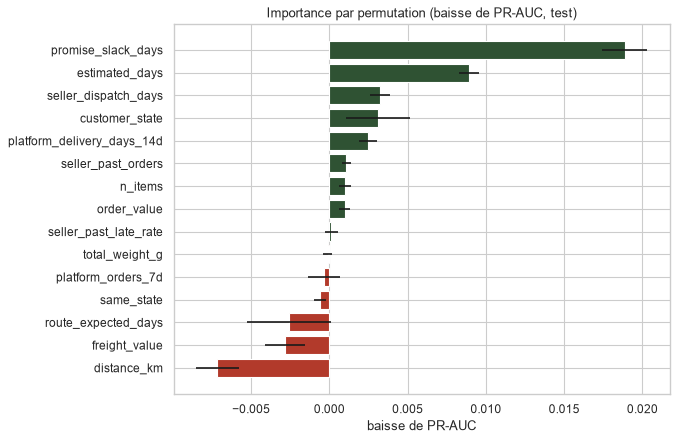

In [13]:
importance = results.importance.set_index("feature").sort_values(
    "importance_mean"
)
fig, ax = plt.subplots(figsize=(8, 6))
colors = np.where(importance["importance_mean"] >= 0, "#2F5233", "#B23A2B")
ax.barh(importance.index, importance["importance_mean"],
        xerr=importance["importance_std"], color=colors)
ax.set(title="Importance par permutation (baisse de PR-AUC, test)",
       xlabel="baisse de PR-AUC")
plt.show()

**Lecture** : la **marge de la promesse** est de loin la variable la plus utile, suivie du délai promis, du délai de préparation du vendeur, de l'état du client et de la vitesse actuelle du réseau. Les importances **négatives** (distance, frais de port, délai du trajet) signifient que la relation apprise sur le passé est fausse sur l'été 2018 : la mélanger améliore le résultat.

## 9. Analyse d'erreurs : qu'est-ce qui a changé à l'été 2018 ?

In [14]:
frame["period"] = np.where(frame["purchase_timestamp"] >= TEST_START,
                          "test", "apprentissage")
bands = {
    "distance_km": [0, 100, 500, 1000, 2000, 5000],
    "estimated_days": [0, 10, 15, 20, 25, 30, 200],
}
for column, edges in bands.items():
    table = frame.pivot_table(
        index=pd.cut(frame[column], edges, include_lowest=True),
        columns="period", values=TARGET, aggfunc="mean", observed=True,
    )
    display((100 * table).round(1).rename_axis(f"{column} (% en retard)"))

period,apprentissage,test
distance_km (% en retard),,
"(-0.001, 100.0]",3.7,6.9
"(100.0, 500.0]",7.0,2.4
"(500.0, 1000.0]",8.2,2.3
"(1000.0, 2000.0]",11.0,3.1
"(2000.0, 5000.0]",13.7,4.9


period,apprentissage,test
estimated_days (% en retard),,
"(-0.001, 10.0]",7.4,11.6
"(10.0, 15.0]",4.5,3.2
"(15.0, 20.0]",8.2,2.6
"(20.0, 25.0]",8.9,2.5
"(25.0, 30.0]",7.9,1.7
"(30.0, 200.0]",6.0,0.7


In [15]:
test = results.test_predictions.merge(
    frame[["order_id", "promise_slack_days", "estimated_days",
           "distance_km"]], on="order_id"
)
late = test[test[TARGET] == 1].copy()
top_cut = test[f"proba_{best}"].quantile(0.9)
late["capté"] = np.where(late[f"proba_{best}"] >= top_cut,
                         "capté (top 10 %)", "manqué")
late.groupby("capté")[["promise_slack_days", "estimated_days",
                       "distance_km"]].agg(["mean", "count"]).round(1)

promise_slack_days       estimated_days       distance_km      
                               mean count           mean count        mean count
capté                                                                           
capté (top 10 %)                2.7   117           18.4   117      1180.8   115
manqué                          3.8   555           12.1   555       339.5   549

**Ce qu'on comprend** :

1. Sur l'apprentissage, le retard augmentait avec la distance. Sur l'été 2018, c'est l'inverse : les commandes à **moins de 100 km** sont les plus souvent en retard, car Olist leur promet désormais des délais très courts (10 jours ou moins : 11,6 % de retards).
2. Le modèle, qui a appris « loin = risqué », signale des commandes lointaines qui arrivent finalement à l'heure, et manque des commandes proches à promesse serrée.
3. Les retards **manqués** sont surtout des commandes proches (≈ 350 km en moyenne contre ≈ 1 200 km pour les retards captés) avec des promesses courtes (≈ 12 jours contre ≈ 18) : exactement le profil devenu risqué à l'été 2018, que le modèle n'a jamais vu dans le passé. Tous ces retards ont en revanche une marge faible (3 à 4 jours contre 12 en moyenne) : la marge reste le bon signal, c'est la relation avec la distance qui a changé.

C'est une **dérive de concept** : la relation entre les variables et la cible a changé à cause d'une décision de l'entreprise (la politique de promesse).

## 10. Limites et recommandations

- **Performance modeste mais utile** : environ 2 fois mieux que le hasard en validation, 1,6 fois sur l'été 2018. À utiliser comme **outil de priorisation** (liste des commandes les plus risquées à surveiller), pas comme une prédiction certaine.
- **Dérive** : réentraîner le modèle chaque mois avec `pipelines/train_flow.py` et surveiller la PR-AUC sur les dernières semaines ; tout changement de politique de promesse doit déclencher un réentraînement.
- **Si la dérive persiste**, la régression logistique, plus robuste sur l'été 2018, est l'alternative à tester en priorité.
- **Améliorations possibles** : données de suivi du transporteur, jours fériés et grèves, météo ; ces informations n'existent pas dans le jeu Olist.
- **Équité** : le modèle utilise l'état du client. Un audit par région (le modèle se trompe-t-il davantage pour certaines régions ?) est réalisé dans la suite du Lot 4.